# Day 5 — Grounded Multimodal Generation

Use retrieved text chunks, captions, and document images to answer questions with source references. Check that each claim is supported by the retrieved context.

## 1. Install dependencies

Install the libraries needed to load the retrieval results and run the vision-language model.

In [2]:
!pip -q install "transformers>=4.57.0" accelerate qwen-vl-utils pillow pandas

In [3]:
!pip install -q -U bitsandbytes accelerate

## 2. Imports

Import the model, image, JSON, and display utilities.

In [4]:
from pathlib import Path
import json
import torch
import pandas as pd
from PIL import Image
from IPython.display import display
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration
from google.colab import files

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


## 3. Upload Day 4 retrieval results

Upload day4_retrieval_results.json from Day 4 and the extracted image files used in the document.

In [5]:
uploaded = files.upload()

import zipfile
from pathlib import Path
import json

json_files = [name for name in uploaded if name.endswith(".json")]
image_extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

retrieval_file = next(
    (name for name in json_files if "day4_retrieval_results" in name),
    None
)

if retrieval_file is None:
    raise ValueError("Upload day4_retrieval_results.json.")

with open(retrieval_file, "r", encoding="utf-8") as file:
    retrieval_data = json.load(file)

image_lookup = {}

for name in uploaded:
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name, "r") as z:
            z.extractall("day2_images")

for path in Path("day2_images").rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        image_lookup[path.name] = str(path)

for name in uploaded:
    if Path(name).suffix.lower() in image_extensions:
        image_lookup[Path(name).name] = name

uploaded_images = list(image_lookup.values())

print("Loaded:", retrieval_file)
print("Uploaded images:", len(uploaded_images))
print("Image files:", list(image_lookup.keys()))

Saving day2_extracted_images.zip to day2_extracted_images.zip
Saving day4_retrieval_results.json to day4_retrieval_results.json
Loaded: day4_retrieval_results.json
Uploaded images: 6
Image files: ['table-1-1.jpg', 'figure-1-1.jpg', 'table-2-4.jpg', 'table-1-2.jpg', 'table-2-5.jpg', 'table-2-3.jpg']


## 4. Select retrieved context

Choose a retrieval mode and collect its results with their source-document and page metadata.

In [16]:
retrieval_mode = "text_plus_image"  # "text_only", "image_only", "text_plus_image"

mode_key = {
    "text_only": "text_only_results",
    "image_only": "image_only_results",
    "text_plus_image": "text_plus_image_results"
}[retrieval_mode]

retrieved_results = retrieval_data.get(mode_key, [])
if not retrieved_results:
    raise ValueError(f"No results found for {retrieval_mode}. Run the corresponding Day 4 retrieval first.")

display(pd.DataFrame([
    {"modality": r.get("modality"), "source_doc": r.get("source_doc"),
     "page": r.get("page"), "similarity": r.get("similarity"), "content": r.get("text")}
    for r in retrieved_results
]))

,modality,source_doc,page,similarity,content
0,text,sample_multimodal_invoice.pdf,2,0.7357,Document Control
1,text,sample_multimodal_invoice.pdf,1,0.7280,Notes: Goods supplied are covered by the manuf...
2,text,sample_multimodal_invoice.pdf,1,0.7192,Original for recipient
3,text,sample_multimodal_invoice.pdf,1,0.7146,Authorised Signatory
4,text,sample_multimodal_invoice.pdf,2,0.7117,Service Summary
5,text,sample_multimodal_invoice.pdf,1,0.7105,Grand Total
6,text,sample_multimodal_invoice.pdf,1,0.7101,Items and Services
7,text,sample_multimodal_invoice.pdf,1,0.7084,Bill To


## 5. Prepare context with source IDs

Assign a citation ID to each retrieved result so answers can point to the exact source record.

In [7]:
context_items = []
for i, record in enumerate(retrieved_results, start=1):
    context_items.append({
        "source_id": f"S{i}",
        "modality": record.get("modality"),
        "content_type": record.get("content_type"),
        "source_doc": record.get("source_doc"),
        "page": record.get("page"),
        "text": record.get("text"),
        "similarity": record.get("similarity"),
        "image_path": record.get("image_path")
    })

for item in context_items:
    print(f"[{item['source_id']}] {item['modality']} | {item['source_doc']} | page {item['page']}\n{item['text']}\n")

[S1] text | sample_multimodal_invoice.pdf | page 2
Document Control

[S2] text | sample_multimodal_invoice.pdf | page 1
Notes: Goods supplied are covered by the manufacturer's standard warranty. Services are deemed accepted after written confirmation by the customer.

[S3] text | sample_multimodal_invoice.pdf | page 1
Original for recipient

[S4] text | sample_multimodal_invoice.pdf | page 1
Authorised Signatory

[S5] text | sample_multimodal_invoice.pdf | page 2
Service Summary

[S6] text | sample_multimodal_invoice.pdf | page 1
Grand Total

[S7] text | sample_multimodal_invoice.pdf | page 1
Items and Services

[S8] text | sample_multimodal_invoice.pdf | page 1
Bill To



## 6. Load Qwen3-VL

Load Qwen3-VL-4B-Instruct to answer questions using retrieved text and visual evidence. A GPU with sufficient memory is recommended.

In [8]:
import torch
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, BitsAndBytesConfig

model_id = "Qwen/Qwen3-VL-4B-Instruct"

processor = AutoProcessor.from_pretrained(model_id)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=quantization_config,
    device_map="auto",
    low_cpu_mem_usage=True
)

print("Loaded:", model_id)

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct


## 7. Prepare retrieved images

Resolve image paths from the uploaded files and select up to three images as visual context.

Images available for the VLM: 3
IMG1 table-1-1.jpg


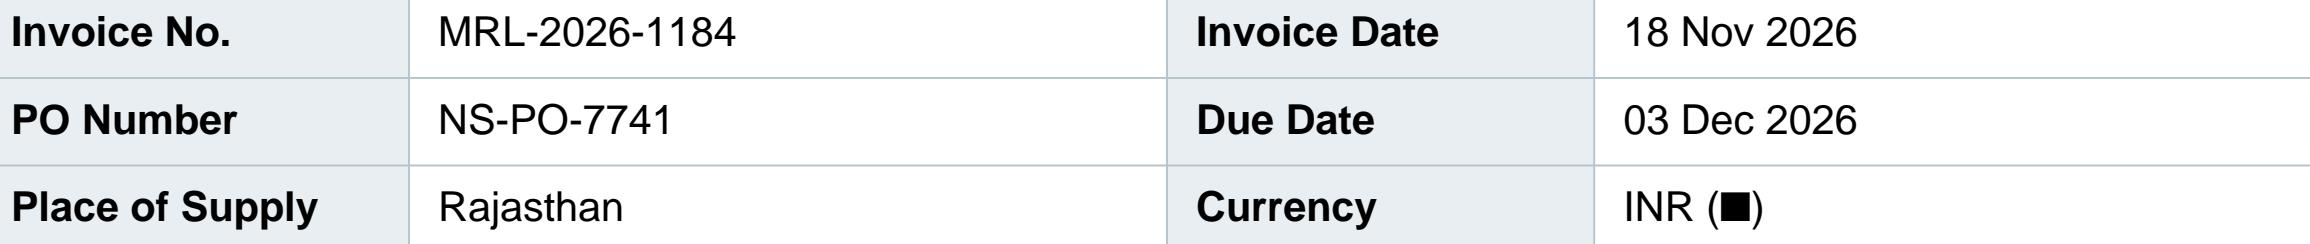

IMG2 figure-1-1.jpg


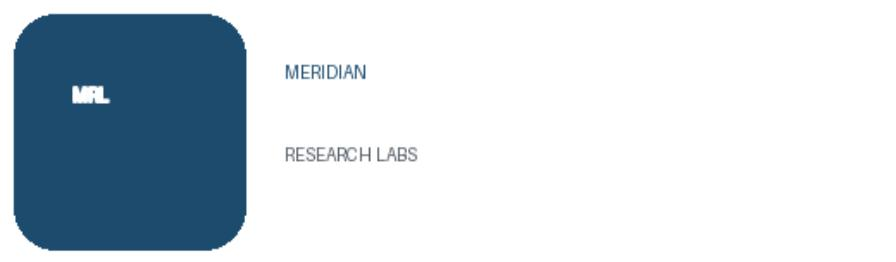

IMG3 table-2-4.jpg


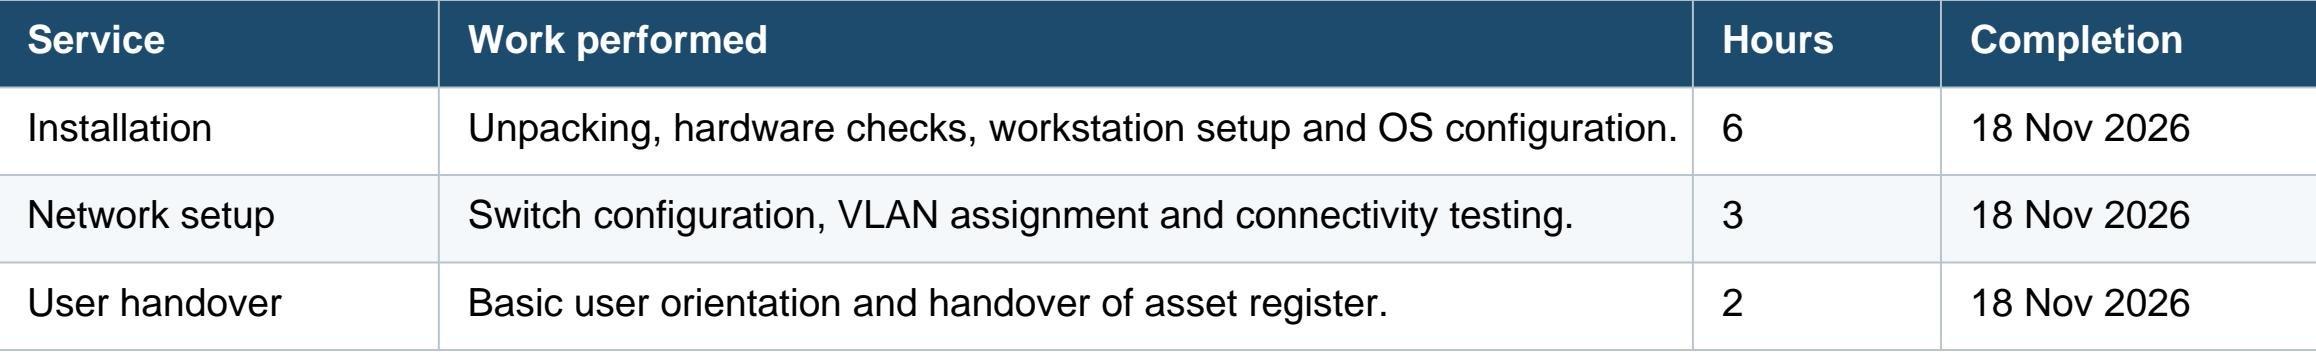

In [9]:
visual_context = []

source_doc = (
    context_items[0].get("source_doc", "uploaded document")
    if context_items else "uploaded document"
)

for i, (filename, path) in enumerate(image_lookup.items()):
    if Path(path).exists():
        visual_context.append({
            "source_id": f"IMG{i+1}",
            "source_doc": source_doc,
            "page": None,
            "modality": "image",
            "image_path": filename,
            "resolved_image_path": path
        })

visual_context = visual_context[:3]

print("Images available for the VLM:", len(visual_context))

for item in visual_context:
    print(item["source_id"], item["image_path"])
    display(Image.open(item["resolved_image_path"]).convert("RGB"))

## 8. Build the grounded prompt

Include retrieved text and source IDs. Require the model to use only this evidence and cite factual statements.

In [10]:
def build_context_text(items):
    return "\n\n".join(
        f"[{item['source_id']}] Modality: {item['modality']} | "
        f"Document: {item['source_doc']} | Page: {item['page']}\n"
        f"Content: {item['text']}"
        for item in items
    )

context_text = build_context_text(context_items)
question = "What equipment and services are listed in the retrieved invoice, and what is the invoice total?"

system_instruction = (
    "Answer using only the supplied retrieved context and attached document images. "
    "Do not guess or use outside knowledge. If evidence is missing, say it is not available "
    "in the retrieved context. Cite factual claims using source IDs exactly as [S1], [S2], etc. "
    "Distinguish image observations from extracted text."
)

print("Question:", question)
print("Context sources:", len(context_items))

Question: What equipment and services are listed in the retrieved invoice, and what is the invoice total?
Context sources: 8


## 9. Generate a grounded answer

Send retrieved text and selected images to Qwen3-VL and generate an answer with source citations.

In [11]:
from qwen_vl_utils import process_vision_info
import torch

content = [
    {
        "type": "text",
        "text": system_instruction + "\n\nRetrieved context:\n" + context_text
    }
]

# Use only one extracted image initially
for item in visual_context[:1]:
    content.append({
        "type": "image",
        "image": item["resolved_image_path"]
    })

content.append({"type": "text", "text": "\nQuestion: " + question})

messages = [{"role": "user", "content": content}]

prompt = processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[prompt],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
).to(model.device)

with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_ids_trimmed = [
    output_ids[len(input_ids):]
    for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
]

answer = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True
)[0]

print(answer)

The retrieved invoice lists "Items and Services" and "Service Summary" as sections, but the specific equipment and services are not detailed in the provided context. The "Grand Total" is also not specified in the retrieved context. Therefore, the equipment and services listed and the invoice total are not available in the retrieved context.


## 10. Review the cited sources

Display the retrieved source records so citations can be checked against their supporting content.

In [17]:
sources_df = pd.DataFrame([
    {"source_id": item["source_id"], "modality": item["modality"],
     "source_doc": item["source_doc"], "page": item["page"],
     "similarity": item["similarity"], "content": item["text"]}
    for item in context_items
])
display(sources_df)

,source_id,modality,source_doc,page,similarity,content
0,S1,text,sample_multimodal_invoice.pdf,2,0.7357,Document Control
1,S2,text,sample_multimodal_invoice.pdf,1,0.7280,Notes: Goods supplied are covered by the manuf...
2,S3,text,sample_multimodal_invoice.pdf,1,0.7192,Original for recipient
3,S4,text,sample_multimodal_invoice.pdf,1,0.7146,Authorised Signatory
4,S5,text,sample_multimodal_invoice.pdf,2,0.7117,Service Summary
5,S6,text,sample_multimodal_invoice.pdf,1,0.7105,Grand Total
6,S7,text,sample_multimodal_invoice.pdf,1,0.7101,Items and Services
7,S8,text,sample_multimodal_invoice.pdf,1,0.7084,Bill To


## 11. Check citation IDs

Check whether the answer uses citation IDs that exist in the retrieved context. This does not prove factual correctness.

In [20]:
import re

used_ids = sorted(set(re.findall(r"\[((?:S|IMG)\d+)\]", answer)))
valid_ids = {item["source_id"] for item in context_items}
invalid_ids = [source_id for source_id in used_ids if source_id not in valid_ids]

print("Citation IDs used:", used_ids)
print("Unknown citation IDs:", invalid_ids)
print("Citation ID check:", "PASS" if used_ids and not invalid_ids else "REVIEW")

Citation IDs used: []
Unknown citation IDs: []
Citation ID check: REVIEW


## 12. Save the answer and provenance

Save the question, answer, retrieval mode, and source metadata for review.

In [21]:
answer_record = {
    "question": question,
    "retrieval_mode": retrieval_mode,
    "model": model_id,
    "answer": answer,
    "used_source_ids": used_ids,
    "citation_id_check": "PASS" if used_ids and not invalid_ids else "REVIEW",
    "sources": context_items
}

output_path = Path("day5_grounded_answer.json")
with open(output_path, "w", encoding="utf-8") as file:
    json.dump(answer_record, file, ensure_ascii=False, indent=2, default=str)
print("Saved:", output_path)

Saved: day5_grounded_answer.json


## 13. Download the result

Download the grounded answer and its source metadata.

In [22]:
files.download(str(output_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notebook summary

This notebook takes retrieved text chunks, image captions, and available document images from Day 4 and passes them to Qwen3-VL with a question. The prompt requires the model to stay within retrieved evidence and cite source IDs. It displays the source records, checks that cited IDs exist, and saves the answer together with its provenance. Citation-ID validation does not guarantee factual correctness; the answer must still be checked against the cited document pages.